In [ ]:
import zipfile

with zipfile.ZipFile('/content/drive/MyDrive/Colab Notebooks/sake_dataset-master.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/drive/MyDrive/Colab Notebooks/')

In [ ]:
import json

with open("/content/drive/MyDrive/Colab Notebooks/sake_dataset-master/json/sake_dataset_v1.json", "r", encoding="utf-8") as f:
    data = json.load(f)

print("データの型:", type(data))
print("データの件数:", len(data) if isinstance(data, (list, dict)) else "確認が必要")

print("\n先頭のデータ:")
print(json.dumps(data[:2] if isinstance(data, list) else data, ensure_ascii=False, indent=2)[:5000])

データの型: <class 'dict'>
データの件数: 2

先頭のデータ:
{
  "dataset": [
    {
      "name": "荒武者",
      "dgree_of_sweetness/dryness": "-0.93",
      "prefecture": "京都府",
      "sake_meter_value": {
        "mean": "11.00",
        "max": "11.00",
        "min": "11.00"
      },
      "amino_acid_content": {
        "mean": "1.20",
        "max": "1.20",
        "min": "1.20"
      },
      "brand": "金閣",
      "method_for_making_sake": [],
      "rice_polishing_rate": "60",
      "alcohol_rate": {
        "mean": "16.50",
        "max": "16.00",
        "min": "17.00"
      },
      "rice": [],
      "brewer": "キンシ正宗",
      "sake_class": "本醸造",
      "titratable_acidity": {
        "mean": "1.30",
        "max": "1.30",
        "min": "1.30"
      },
      "city": "京都市伏見区",
      "yeast": [],
      "brand+name": "金閣 荒武者"
    },
    {
      "name": "",
      "dgree_of_sweetness/dryness": "-0.24",
      "prefecture": "京都府",
      "sake_meter_value": {
        "mean": "1.00",
        "max": "1.00",
 

In [ ]:
import pandas as pd

# 銘柄データを取り出し、表形式に変換する
df = pd.json_normalize(data["dataset"])

# 1. データの件数と項目数
print("データの形状（行数, 列数）:", df.shape)

# 2. 項目名
print("\n項目名:")
print(df.columns.tolist())

# 3. 甘辛度の分布
target = "dgree_of_sweetness/dryness"
print("\n甘辛度の基本統計量:")
print(pd.to_numeric(df[target], errors="coerce").describe())

# 4. 主な項目の先頭5件
columns_to_check = [
    "name",
    "brand",
    "dgree_of_sweetness/dryness",
    "sake_meter_value.mean",
    "amino_acid_content.mean",
    "rice_polishing_rate",
    "alcohol_rate.mean",
    "titratable_acidity.mean"
]

print("\n主な項目の先頭5件:")
display(df[columns_to_check].head())

# 5. 欠損値・空文字の数
print("\n欠損値の数:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

print("\n空文字の数:")
print(
    df.astype("string")
      .apply(lambda col: col.str.strip().eq("").sum())
      .sort_values(ascending=False)
      .head(20)
)

データの形状（行数, 列数）: (1294, 24)

項目名:
['name', 'dgree_of_sweetness/dryness', 'prefecture', 'brand', 'method_for_making_sake', 'rice_polishing_rate', 'rice', 'brewer', 'sake_class', 'city', 'yeast', 'brand+name', 'sake_meter_value.mean', 'sake_meter_value.max', 'sake_meter_value.min', 'amino_acid_content.mean', 'amino_acid_content.max', 'amino_acid_content.min', 'alcohol_rate.mean', 'alcohol_rate.max', 'alcohol_rate.min', 'titratable_acidity.mean', 'titratable_acidity.max', 'titratable_acidity.min']

甘辛度の基本統計量:
count    1228.000000
mean       -0.388225
std         0.793198
min        -7.500000
25%        -0.660000
50%        -0.400000
75%        -0.150000
max        12.010000
Name: dgree_of_sweetness/dryness, dtype: float64

主な項目の先頭5件:


,name,brand,dgree_of_sweetness/dryness,sake_meter_value.mean,amino_acid_content.mean,rice_polishing_rate,alcohol_rate.mean,titratable_acidity.mean
0,荒武者,金閣,-0.93,11.00,1.20,60,16.50,1.30
1,,金閣,-0.24,1.00,1.30,65,16.50,1.50
2,,松屋久兵衛,0.11,1.00,1.10,35,16.50,1.20
3,純米大吟醸 祝,金鵄正宗,0.11,1.00,1.10,45,16.50,1.20
4,純米大吟醸,切子,0.11,1.00,1.10,45,16.50,1.20



欠損値の数:
name                          0
dgree_of_sweetness/dryness    0
prefecture                    0
brand                         0
method_for_making_sake        0
rice_polishing_rate           0
rice                          0
brewer                        0
sake_class                    0
city                          0
yeast                         0
brand+name                    0
sake_meter_value.mean         0
sake_meter_value.max          0
sake_meter_value.min          0
amino_acid_content.mean       0
amino_acid_content.max        0
amino_acid_content.min        0
alcohol_rate.mean             0
alcohol_rate.max              0
dtype: int64

空文字の数:
amino_acid_content.max        532
amino_acid_content.min        532
amino_acid_content.mean       532
alcohol_rate.mean             357
alcohol_rate.min              357
alcohol_rate.max              357
dgree_of_sweetness/dryness     66
titratable_acidity.mean        63
titratable_acidity.min         63
titratable_acidity.max   

In [ ]:
# 空文字や空白だけの文字列を欠損値に変換する
df_clean = df.replace(r"^\s*$", pd.NA, regex=True)

# 甘辛度を数値に変換する
target = "dgree_of_sweetness/dryness"
df_clean[target] = pd.to_numeric(
    df_clean[target], errors="coerce"
)

# 甘辛度の欠損件数を確認する
print("甘辛度の欠損件数:", df_clean[target].isna().sum())

# 甘辛度が小さい銘柄を5件表示する
print("\n甘辛度が小さい銘柄:")
display(
    df_clean.sort_values(target)[
        ["brand+name", target, "sake_meter_value.mean",
         "titratable_acidity.mean"]
    ].head(5)
)

# 甘辛度が大きい銘柄を5件表示する
print("\n甘辛度が大きい銘柄:")
display(
    df_clean.sort_values(target, ascending=False)[
        ["brand+name", target, "sake_meter_value.mean",
         "titratable_acidity.mean"]
    ].head(5)
)

# 候補となる入力項目の欠損件数を確認する
features = [
    "rice_polishing_rate",
    "alcohol_rate.mean",
    "amino_acid_content.mean",
    "titratable_acidity.mean",
    "sake_meter_value.mean"
]

print("\n入力候補の欠損件数:")
print(df_clean[features].isna().sum())

甘辛度の欠損件数: 66

甘辛度が小さい銘柄:


,brand+name,dgree_of_sweetness/dryness,sake_meter_value.mean,titratable_acidity.mean
1025,天寿 旨口純米酒,-7.50,3.00,7.60
15,酒呑童子 斗瓶取り雫酒 黒瓶,-6.65,5.00,6.70
902,多満自慢 純米吟醸 夏の生酒,-2.97,-12.00,4.90
1223,鳴門鯛 純米吟醸原酒 大古酒 月読酒,-2.62,13.00,2.60
656,美田 山廃純米 大辛口 辛醸,-2.14,14.00,2.10



甘辛度が大きい銘柄:


,brand+name,dgree_of_sweetness/dryness,sake_meter_value.mean,titratable_acidity.mean
826,若竹屋 博多練酒,12.01,-122.00,1.70
71,一ノ蔵 すず音,5.40,-80.00,3.50
743,春鹿 ときめき,5.20,-100.00,5.50
83,一ノ蔵 すず音Ｗａｂｉ,4.89,-75.00,3.50
829,五橋 ねね,4.77,-85.00,4.50



入力候補の欠損件数:
rice_polishing_rate         21
alcohol_rate.mean          357
amino_acid_content.mean    532
titratable_acidity.mean     63
sake_meter_value.mean       50
dtype: int64


In [ ]:
import pandas as pd

# 予測対象（正解データ）
target = "dgree_of_sweetness/dryness"

# 入力に使う4項目
features = [
    "rice_polishing_rate",       # 精米歩合
    "alcohol_rate.mean",         # アルコール度数
    "amino_acid_content.mean",   # アミノ酸度
    "titratable_acidity.mean"    # 酸度
]

# 入力項目を数値に変換する
for col in features:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

# 予測対象も数値に変換する
df_clean[target] = pd.to_numeric(
    df_clean[target], errors="coerce"
)

# 入力4項目と正解データがすべてそろった行だけを抽出する
df_model = df_clean[features + [target]].dropna().copy()

print("元のデータ件数:", len(df_clean))
print("学習に使えるデータ件数:", len(df_model))
print("除外されたデータ件数:", len(df_clean) - len(df_model))

print("\n学習用データの先頭5件:")
display(df_model.head())

print("\n各項目の基本統計量:")
display(df_model.describe())

元のデータ件数: 1294
学習に使えるデータ件数: 755
除外されたデータ件数: 539

学習用データの先頭5件:


,rice_polishing_rate,alcohol_rate.mean,amino_acid_content.mean,titratable_acidity.mean,dgree_of_sweetness/dryness
0,60.0,16.5,1.2,1.3,-0.93
1,65.0,16.5,1.3,1.5,-0.24
2,35.0,16.5,1.1,1.2,0.11
3,45.0,16.5,1.1,1.2,0.11
4,45.0,16.5,1.1,1.2,0.11



各項目の基本統計量:


,rice_polishing_rate,alcohol_rate.mean,amino_acid_content.mean,titratable_acidity.mean,dgree_of_sweetness/dryness
count,755.000000,755.000000,755.000000,755.000000,755.000000
mean,57.825166,15.590397,1.206358,1.613775,-0.356119
std,9.069941,1.521751,0.373695,0.655488,0.862929
min,23.000000,4.000000,0.150000,1.000000,-7.500000
25%,55.000000,15.000000,1.000000,1.300000,-0.650000
50%,60.000000,15.500000,1.200000,1.500000,-0.380000
75%,65.000000,16.000000,1.400000,1.700000,-0.115000
max,90.000000,20.000000,7.600000,8.000000,12.010000


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# 入力データ（4項目）
X = df_model[features]

# 正解データ（甘辛度）
y = df_model[target]

# 学習用80%、テスト用20%に分割する
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("学習用データ件数:", len(X_train))
print("テスト用データ件数:", len(X_test))

# モデルを作成する
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

# 学習用データから規則を学習する
model.fit(X_train, y_train)

# テスト用データの甘辛度を予測する
y_pred = model.predict(X_test)

# 予測性能を評価する
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n評価結果")
print(f"MAE（平均絶対誤差）: {mae:.3f}")
print(f"RMSE（二乗平均平方根誤差）: {rmse:.3f}")
print(f"R²（決定係数）: {r2:.3f}")

学習用データ件数: 604
テスト用データ件数: 151

評価結果
MAE（平均絶対誤差）: 0.268
RMSE（二乗平均平方根誤差）: 0.497
R²（決定係数）: 0.089


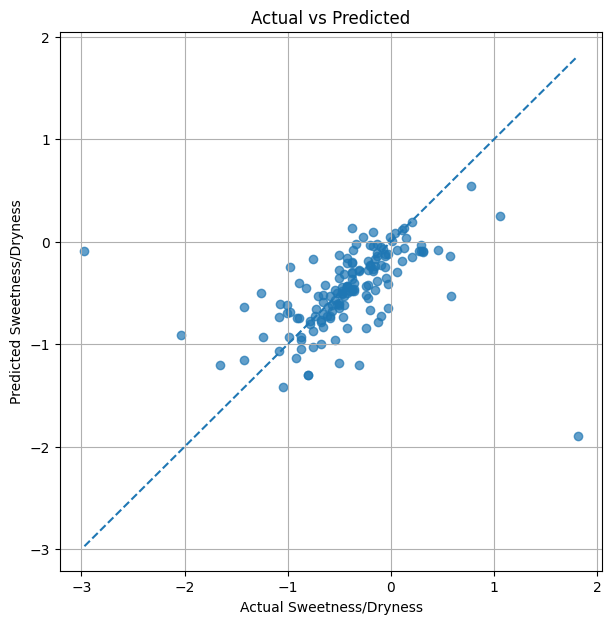

In [ ]:
import matplotlib.pyplot as plt

# 実際の値と予測値を比較する散布図
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.7)

# 実際の値と予測値が完全に一致する場合の基準線
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Sweetness/Dryness")
plt.ylabel("Predicted Sweetness/Dryness")
plt.title("Actual vs Predicted")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 日本酒度を含めた5項目を用意する
features_with_smv = features + ["sake_meter_value.mean"]

# 日本酒度を数値に変換する
df_clean["sake_meter_value.mean"] = pd.to_numeric(
    df_clean["sake_meter_value.mean"], errors="coerce"
)

# 5項目すべてと甘辛度がそろっているデータを抽出
df_model_smv = df_clean[
    features_with_smv + [target]
].dropna().copy()

print("日本酒度を含めた場合のデータ件数:", len(df_model_smv))

# 前回と同じテストデータの行を使うため、元の行番号を利用する
test_indices = X_test.index.intersection(df_model_smv.index)

X_train_smv = df_model_smv.loc[
    ~df_model_smv.index.isin(X_test.index), features_with_smv
]
y_train_smv = df_model_smv.loc[X_train_smv.index, target]

X_test_smv = df_model_smv.loc[test_indices, features_with_smv]
y_test_smv = df_model_smv.loc[test_indices, target]

print("比較用の学習データ件数:", len(X_train_smv))
print("比較用のテストデータ件数:", len(X_test_smv))

# 日本酒度を含めたモデルを学習
model_smv = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model_smv.fit(X_train_smv, y_train_smv)

# 予測と評価
y_pred_smv = model_smv.predict(X_test_smv)

mae_smv = mean_absolute_error(y_test_smv, y_pred_smv)
rmse_smv = np.sqrt(mean_squared_error(y_test_smv, y_pred_smv))
r2_smv = r2_score(y_test_smv, y_pred_smv)

print("\n日本酒度を含めたモデルの評価結果")
print(f"MAE: {mae_smv:.3f}")
print(f"RMSE: {rmse_smv:.3f}")
print(f"R²: {r2_smv:.3f}")

# 前回のモデルとの比較
print("\n前回のモデル（4項目）")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²: {r2:.3f}")

日本酒度を含めた場合のデータ件数: 755
比較用の学習データ件数: 604
比較用のテストデータ件数: 151

日本酒度を含めたモデルの評価結果
MAE: 0.056
RMSE: 0.259
R²: 0.753

前回のモデル（4項目）
MAE: 0.268
RMSE: 0.497
R²: 0.089


In [ ]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 入力項目は日本酒度を除いた4項目
features = [
    "rice_polishing_rate",
    "alcohol_rate.mean",
    "amino_acid_content.mean",
    "titratable_acidity.mean"
]

target = "dgree_of_sweetness/dryness"

# 学習データを準備
X = df_model[features]
y = df_model[target]

# 学習用80%、テスト用20%に分割
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# モデルを学習
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
model.fit(X_train, y_train)

# 予測性能を確認
y_pred = model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("R²:", round(r2_score(y_test, y_pred), 3))

# 学習済みモデルを保存
joblib.dump(model, "sake_model.joblib")

# 入力項目の順番も保存
joblib.dump(features, "sake_features.joblib")

print("\nモデルを保存しました。")

MAE: 0.268
R²: 0.089

モデルを保存しました。


In [ ]:
print("df:", "df" in globals())
print("df_clean:", "df_clean" in globals())
print("df_model:", "df_model" in globals())

df: True
df_clean: True
df_model: True


In [ ]:
print(df.columns.tolist())

['name', 'dgree_of_sweetness/dryness', 'prefecture', 'brand', 'method_for_making_sake', 'rice_polishing_rate', 'rice', 'brewer', 'sake_class', 'city', 'yeast', 'brand+name', 'sake_meter_value.mean', 'sake_meter_value.max', 'sake_meter_value.min', 'amino_acid_content.mean', 'amino_acid_content.max', 'amino_acid_content.min', 'alcohol_rate.mean', 'alcohol_rate.max', 'alcohol_rate.min', 'titratable_acidity.mean', 'titratable_acidity.max', 'titratable_acidity.min']


In [ ]:
import pandas as pd
import numpy as np

# 検証に使う列
target = "dgree_of_sweetness/dryness"
smv_col = "sake_meter_value.mean"
acidity_col = "titratable_acidity.mean"

# 必要な列だけを取り出してコピー
df_formula = df[[target, smv_col, acidity_col]].copy()

# 空文字や数値以外の値を欠損値に変換
for col in [target, smv_col, acidity_col]:
    df_formula[col] = pd.to_numeric(
        df_formula[col], errors="coerce"
    )

# 3項目すべてが揃っているデータだけを残す
df_formula = df_formula.dropna().copy()

print("比較対象のデータ件数:", len(df_formula))
display(df_formula.head())

比較対象のデータ件数: 1228


,dgree_of_sweetness/dryness,sake_meter_value.mean,titratable_acidity.mean
0,-0.93,11.0,1.3
1,-0.24,1.0,1.5
2,0.11,1.0,1.2
3,0.11,1.0,1.2
4,0.11,1.0,1.2


In [ ]:
# 計算式による甘辛度
df_formula["calculated_sweetness"] = (
    193593 / (1443 + df_formula[smv_col])
    - 1.16 * df_formula[acidity_col]
    - 132.57
)

# 実データとの差
df_formula["difference"] = (
    df_formula[target]
    - df_formula["calculated_sweetness"]
)

display(
    df_formula[
        [
            target,
            smv_col,
            acidity_col,
            "calculated_sweetness",
            "difference"
        ]
    ].head(10).round(3)
)

,dgree_of_sweetness/dryness,sake_meter_value.mean,titratable_acidity.mean,calculated_sweetness,difference
0,-0.93,11.0,1.3,-0.933,0.003
1,-0.24,1.0,1.5,-0.243,0.003
2,0.11,1.0,1.2,0.105,0.005
3,0.11,1.0,1.2,0.105,0.005
4,0.11,1.0,1.2,0.105,0.005
5,0.06,1.5,1.2,0.059,0.001
6,-0.17,1.5,1.4,-0.173,0.003
7,-0.52,4.0,1.5,-0.521,0.001
8,-0.93,11.0,1.3,-0.933,0.003
9,-0.70,8.5,1.3,-0.704,0.004


In [ ]:
# 差の絶対値
df_formula["absolute_difference"] = (
    df_formula["difference"].abs()
)

print("比較対象の件数:", len(df_formula))
print(
    "平均絶対誤差:",
    round(df_formula["absolute_difference"].mean(), 4)
)
print(
    "誤差の中央値:",
    round(df_formula["absolute_difference"].median(), 4)
)
print(
    "誤差0.1以内の割合:",
    round(
        (df_formula["absolute_difference"] <= 0.1).mean() * 100,
        2
    ),
    "%"
)
print(
    "誤差0.5以内の割合:",
    round(
        (df_formula["absolute_difference"] <= 0.5).mean() * 100,
        2
    ),
    "%"
)

比較対象の件数: 1228
平均絶対誤差: 0.0026
誤差の中央値: 0.0027
誤差0.1以内の割合: 100.0 %
誤差0.5以内の割合: 100.0 %


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

target = "dgree_of_sweetness/dryness"

features_4 = [
    "rice_polishing_rate",
    "alcohol_rate.mean",
    "amino_acid_content.mean",
    "titratable_acidity.mean"
]

features_5 = features_4 + [
    "sake_meter_value.mean"
]

# 5項目すべてと目的変数が揃ったデータを使う
comparison_df = df_clean[features_5 + [target]].copy()

for col in features_5 + [target]:
    comparison_df[col] = pd.to_numeric(
        comparison_df[col], errors="coerce"
    )

comparison_df = comparison_df.dropna()

print("比較に使うデータ件数:", len(comparison_df))

# 4項目・5項目モデルで共通の学習用／テスト用データを作る
train_df, test_df = train_test_split(
    comparison_df,
    test_size=0.2,
    random_state=42
)

results = []

for name, features in [
    ("日本酒度なし（4項目）", features_4),
    ("日本酒度あり（5項目）", features_5)
]:
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )

    model.fit(train_df[features], train_df[target])

    pred = model.predict(test_df[features])
    actual = test_df[target]

    results.append({
        "モデル": name,
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R²": r2_score(actual, pred)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

比較に使うデータ件数: 755


,モデル,MAE,RMSE,R²
0,日本酒度なし（4項目）,0.2685,0.4974,0.0894
1,日本酒度あり（5項目）,0.0561,0.2500,0.7699
